# DSMEM workloads on the H100 NVL roofline

Every workload here exists in a version that exchanges data between the CTAs of a thread-block cluster through
distributed shared memory (DSMEM) and in a version that does not. Both run on one H100 NVL (GPU 3, SM clock locked at
1635 MHz). Logic and figures: `roofline_figures.py`; inputs: `../workloads/*.yaml`, `../results/*.csv`.

**Findings**
- DSMEM made a kernel faster in two cases. It let a cluster **read a row from HBM once** instead of once per pass
  (CREDIT: 1.2–1.6× on long rows). It let **8 SMs share one row** (top-k: 1.2–1.4×).
- **TMA multicast** in GEMMs changed little (−4 % to +4 %): it saves L2 reads, and these GEMMs are compute-bound.
- **Fused decode kernels** (ClusterFusion) were slower than the kernel sequence they replace (0.62–0.66× in kernel
  time). A decode step's intermediates are ~0.1 % of its HBM bytes, so fusion barely moves the operational intensity.
- **No workload uses more than 2 % of the SM-to-SM bandwidth.**

In [1]:
import roofline_figures as rf
L = rf.load()
C = L["C"]
rf.table_setup(C, L["P"])

,
device,"NVIDIA H100 NVL, 132 SMs (GPU 3)"
driver / CUDA,580.126.20 / 12.9
SM clock,locked at 1635 MHz for every timed and ncu run; memory clock 2619 MHz
ceilings run,2026-10-26T16:30:40.078+00:00
toolchain,"image h100-roofline:cuda12.9.1-83734cedf58e (CUDA 12.9.1, nvcc 12.9.86, Nsight Compute 2025.2.1, Nsight Systems 2025.1.3, PyTorch 2.11.0+cu129, Triton 3.6.0, flashinfer 0.7.2.post1)"
timing,"kernel durations from nsys (20 warm-up + 100 iterations, L2 flushed before each); bytes and instruction counts from ncu (--clock-control none --cache-control all)"
points rows,"16753 (16600 timed reps, 153 counter rows)"
clock-flagged timed reps,0
registered runs,"89 (87 complete); first 2026-10-26T15:03:56.477+00:00, last 2026-10-26T16:44:07.294+00:00"


**Terms.** *Ceiling*: best rate of one resource, measured by a microbenchmark at the locked clock.
*Operational intensity*: work (FLOP, or integer ops) per HBM byte. *Ridge*: the intensity where a compute roof meets
the HBM slope. *Marker* of a version: its fastest configuration at a shape.

## 1. The device

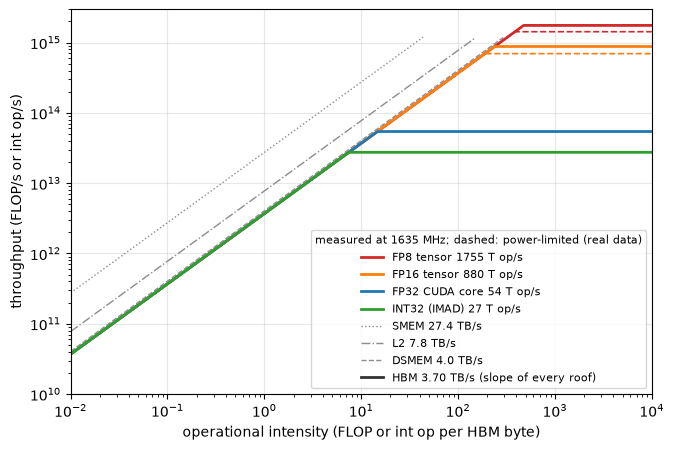

In [2]:
rf.fig_ceilings(C)

In [3]:
rf.table_ceilings(C)

,measured,unit,datasheet,peak at lock,measured / peak at lock,ridge vs HBM (op/B)
ceiling,,,,,,
FP8 tensor,1755.3,TFLOP/s,1670.5,1768.0,99%,474.5
BF16 tensor,879.2,TFLOP/s,835.5,884.0,99%,237.7
FP16 tensor,879.5,TFLOP/s,835.5,884.0,99%,237.8
FP32 CUDA core,54.3,TFLOP/s,60.0,55.2,98%,14.7
INT32 (IMAD),27.5,Tintop/s,—,27.6,99%,7.4
SMEM,27.4,TB/s,—,—,—,—
L2,7.8,TB/s,—,—,—,—
DSMEM,4.0,TB/s,—,—,—,—
HBM,3.7,TB/s,3.9,3.9,95%,—


- Every compute roof is within 1–2 % of the architectural peak at 1635 MHz. HBM reaches 95 % of its datasheet value.
- **Power limit:** with real data, the 400 W limit lowers the clock under dense tensor work. The dashed roofs are what
  random-operand wgmma loops sustain: 696 TFLOP/s FP16, 1428 FP8.
- **DSMEM:** the chip-wide SM-to-SM bandwidth (table below) is 4.0 TB/s at best. That is below L2 (7.8) and barely
  above HBM (3.7). Forwarding data between SMs is not a faster path than L2 in aggregate.

In [4]:
rf.table_dsmem(C)

,"pull (ld.shared::cluster.v4), TB/s","push (bulk copy), TB/s"
cluster size,,
2,3.54,4.04
4,2.77,3.24
8,2.78,2.93
16,2.59,2.49


## 2. How the workloads use DSMEM

The table says what each DSMEM version does with its cluster, what it replaces, and how many bytes it sends SM to
SM. The figure compares the bandwidth each one achieves with the ceilings.

In [5]:
rf.table_dsmem_use(L)

,cluster,what goes through DSMEM / the cluster,replaces,DSMEM KB per run,multicast MB per run,HBM MB per run
workload,,,,,,
clusterfusion deepseek v2 lite mla,4 CTAs per head (16 clusters),"as Llama, plus an all-gather of the latent query",10 kernels handing results over in global memory,540.7,0.0,32.8
clusterfusion llama2 7b decoder,4 CTAs per head (32 clusters),"each CTA computes 1/4 of a head's GEMVs and attention; partial q|k|v (768 B) and attention outputs (256 B) are all-reduced by bulk-copy pushes, norm / softmax scalars by remote atomics",18 kernels handing results over in global memory,327.7,0.0,204.5
clusterfusion rmsnorm,2 CTAs per row,one remote atomicAdd of the partial sum of squares + 2 cluster barriers,one CTA per row,12.3,0.0,1.1
lars momentum,"P = 2, 4, 8 CTAs per row",each CTA keeps 1/P of the row in its shared memory; the row statistics (1–3 floats per pass) are all-reduced by pushing them into every peer's shared memory (st.shared::cluster) + cluster barrier,re-reading the row from HBM/L2 once per pass,"14,680.1",0.0,"5,348.1"
layernorm bwd,"P = 2, 4, 8 CTAs per row",each CTA keeps 1/P of the row in its shared memory; the row statistics (1–3 floats per pass) are all-reduced by pushing them into every peer's shared memory (st.shared::cluster) + cluster barrier,re-reading the row from HBM/L2 once per pass,"14,680.1",0.0,"1,697.4"
pearson bwd,"P = 2, 4, 8 CTAs per row",each CTA keeps 1/P of the row in its shared memory; the row statistics (1–3 floats per pass) are all-reduced by pushing them into every peer's shared memory (st.shared::cluster) + cluster barrier,re-reading the row from HBM/L2 once per pass,"36,700.2",0.0,"4,269.5"
rowwise quant,"P = 2, 4, 8 CTAs per row",each CTA keeps 1/P of the row in its shared memory; the row statistics (1–3 floats per pass) are all-reduced by pushing them into every peer's shared memory (st.shared::cluster) + cluster barrier,re-reading the row from HBM/L2 once per pass,"7,340.0",0.0,"1,334.1"
softmax logits bwd,"P = 2, 4, 8 CTAs per row",each CTA keeps 1/P of the row in its shared memory; the row statistics (1–3 floats per pass) are all-reduced by pushing them into every peer's shared memory (st.shared::cluster) + cluster barrier,re-reading the row from HBM/L2 once per pass,"22,020.1",0.0,"3,203.9"
weighted var bwd,"P = 2, 4, 8 CTAs per row",each CTA keeps 1/P of the row in its shared memory; the row statistics (1–3 floats per pass) are all-reduced by pushing them into every peer's shared memory (st.shared::cluster) + cluster barrier,re-reading the row from HBM/L2 once per pass,"44,040.2",0.0,"4,284.9"


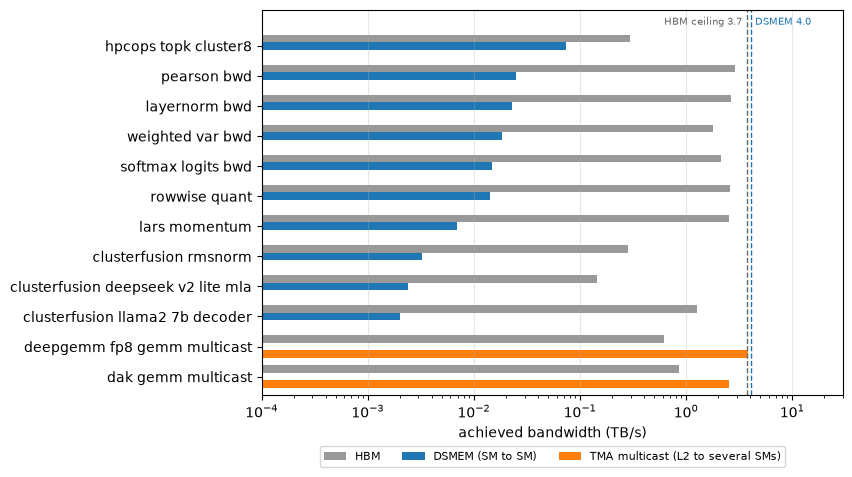

In [6]:
rf.fig_fabric_use(L)

- **Three ways to use a cluster appear.**
  - *Pooled shared memory* (CREDIT): P CTAs together hold a row that one CTA could not.
  - *One load delivered to several SMs* (TMA multicast in DAK, DeepGEMM).
  - *Splitting one unit of work over several SMs* and combining partial results through DSMEM (top-k, ClusterFusion,
    RMSNorm).
- **The exchanges are small.** A few floats per row, a 768-byte vector per head, a 2048-bin histogram. DSMEM traffic
  is 0.05–1.8 % of the DSMEM ceiling and 0.2–1.7 % of the HBM traffic (top-k: 25–170 %). Multicast loads reach 2.5–3.9
  TB/s, but they travel the L2→SM crossbar, not the SM-to-SM network.
- **Unused bandwidth does not make a kernel faster by itself.** A kernel speeds up only when traffic that limits it
  moves onto the fabric: data several SMs now read from HBM or L2 would have to be read once and forwarded. None of
  these kernels is written that way. They use DSMEM for synchronisation-sized exchanges, so their speed depends on
  latency and on how many SMs work, not on fabric bandwidth.

## 3. Where the workloads sit on the roofline

One panel per way of using DSMEM, one shape per workload. Grey circle: non-DSMEM version; triangle: DSMEM version.
Solid roof: measured peak; dashed: power-limited.

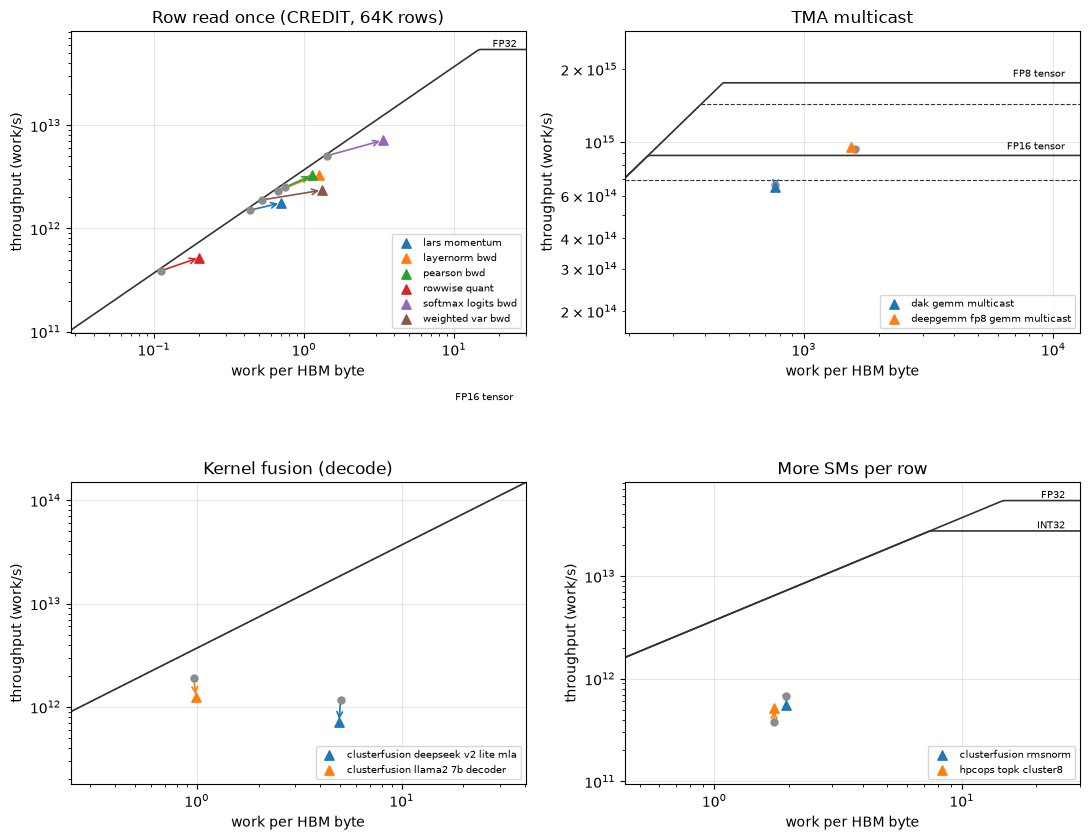

In [7]:
rf.fig_roofline_groups(L)

- **A roofline answers two questions.** Does the DSMEM version move fewer HBM bytes (the arrow points right)? How
  close does each version get to a limit (its height)?
- **Only CREDIT's arrows point right.** Every other DSMEM version moves the same bytes, so its arrow is vertical.
- **A roofline cannot say why a point sits below its roof:** latency, synchronisation, or too few active SMs. That is
  why the effect of DSMEM is shown directly in the next sections, as time and bytes.

## 4. What DSMEM changes: time against bytes

Every measured pair at every shape. Below the horizontal line the DSMEM version is faster. On the diagonal its time
falls exactly as much as its HBM bytes.

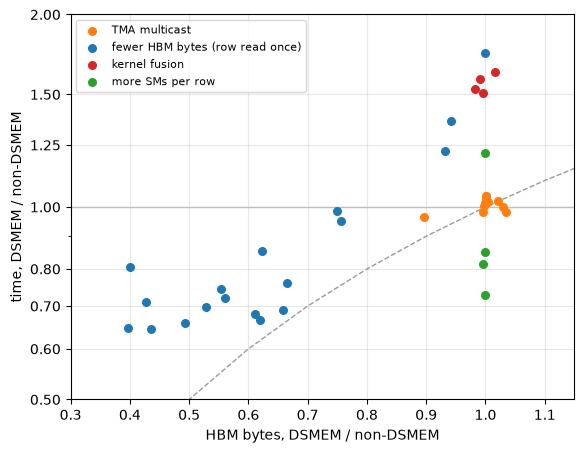

In [8]:
rf.fig_speedup_vs_bytes(L)

In [9]:
rf.table_summary(L)

,how DSMEM is used,shapes,speedup min,speedup max,HBM bytes ratio min,HBM bytes ratio max,DSMEM bytes per HBM byte (max)
workload,,,,,,,
clusterfusion deepseek v2 lite mla,kernel fusion,1,0.62,0.62,1.02,1.02,0.017
clusterfusion llama2 7b decoder,kernel fusion,3,0.63,0.66,0.98,1.00,0.002
clusterfusion rmsnorm,more SMs per row,1,0.82,0.82,1.00,1.00,0.011
lars momentum,fewer HBM bytes (row read once),3,1.17,1.50,0.61,0.62,0.011
layernorm bwd,fewer HBM bytes (row read once),3,0.82,1.52,0.49,0.93,0.009
pearson bwd,fewer HBM bytes (row read once),3,1.05,1.45,0.66,0.76,0.009
rowwise quant,fewer HBM bytes (row read once),3,0.57,1.39,0.55,1.00,0.006
softmax logits bwd,fewer HBM bytes (row read once),3,0.73,1.55,0.43,0.94,0.007
weighted var bwd,fewer HBM bytes (row read once),3,1.01,1.55,0.40,0.75,0.010


- **CREDIT (blue)** is the only group that saves HBM bytes. It gains wherever it saves enough of them. Every point
  lies above the diagonal, because the staged kernels stream more slowly than the plain read kernel.
- **More SMs per row (green):** top-k gains at unchanged bytes. ClusterFusion's RMSNorm, already fast with one CTA
  per row, loses.
- **Multicast (orange)** stays on the line: unchanged bytes, unchanged time.
- **Fusion (red)** loses at unchanged bytes.

## 5. Row reductions (CREDIT): which cluster size?

Six fp32 row-wise kernels (layernorm, softmax and Pearson backward, weighted variance, LARS, int8 quantisation) need
row statistics before writing each row. Cells give the speedup over the one-CTA read kernel. The staged control and
P = 2 need the row slice to fit in 227 KiB, so some 64K-row cells are missing.

In [10]:
rf.table_credit_p(L)

- **Rows of 4K:** the read kernel's second pass hits L2. P = 2 is the best cluster and still loses for three
  workloads.
- **Rows of 16K–64K:** the read kernel's re-reads go to HBM. Clusters win (1.2–1.6×), and the best P grows with the
  row: 2 at 4K, 2–8 at 16K, 8 at 64K.
- **Cost of large P:** it multiplies per-row work that every CTA repeats (divisions, block reductions). With P = 8,
  4K rows run up to 6× slower than the read kernel.
- **Cluster sizes:** CREDIT is the only workload whose cluster size could be swept (its binary caps P at 8). The others
  are fixed by their code: DAK 2, DeepGEMM 1 or 2, top-k 8, ClusterFusion 1 or 4 (the only correct sizes),
  RMSNorm 2.

## 6. TMA multicast in GEMMs (DAK, DeepGEMM)

A cluster of 2 CTAs loads each shared operand tile once from L2 and multicasts it into both SMs. The baseline is the
same kernel without the cluster. Ratios below 1 mean multicast is cheaper.

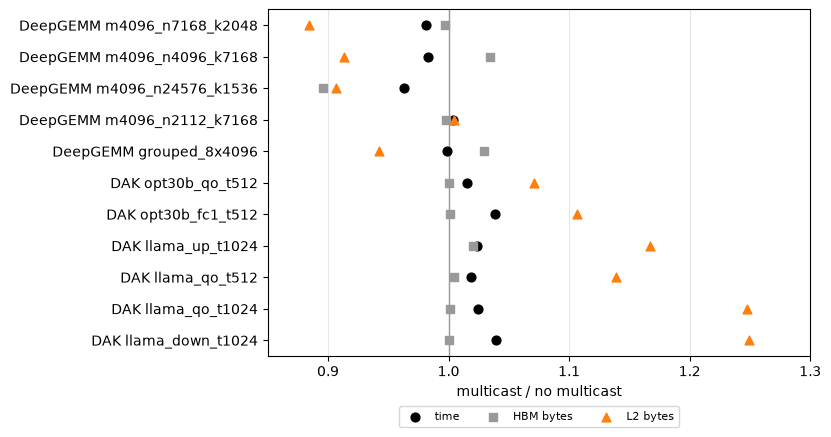

In [11]:
rf.fig_multicast(L)

- **HBM bytes:** unchanged (squares at 1). L2 already serves the second reader of a tile, so multicast cannot
  reduce HBM traffic.
- **L2 bytes:** DeepGEMM saves 6–12 % at four of five shapes. For DAK, ncu reports more L2 bytes with multicast; how it counts multicast
  requests is not settled.
- **Time:** −4 % to +4 %. With K loops of 1.5–7k per tile, the tensor cores set the time, not operand delivery.
- **Bugs fixed:** DAK's multicast kernel shipped with two races, fixed before timing (appendix B). cuBLASLt itself
  uses multicast clusters and matches DeepGEMM within ±4 %.

## 7. Fused decode (ClusterFusion): does fusion raise the intensity?

ClusterFusion fuses a decode step's attention block (Llama-2-7B) or MLA (DeepSeek-V2-Lite) into one kernel: one
4-CTA cluster per head, partial results combined through DSMEM. The intuition to test: keeping intermediates on
chip removes HBM traffic, so intensity and FLOP/s rise. First, where a decode step's HBM bytes come from:

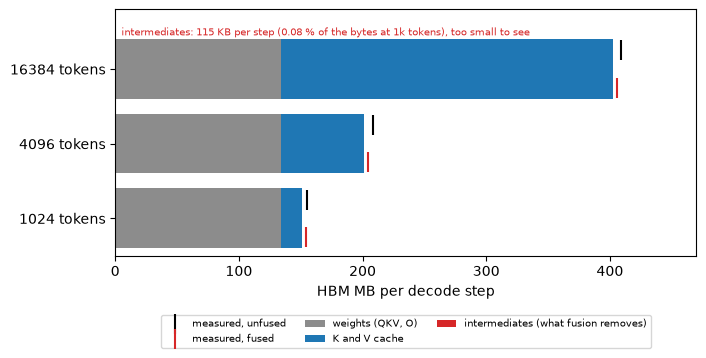

In [12]:
rf.fig_decode_bytes(L)

- **The bytes are the weights and the KV cache**, read once per step by either version (150–400 MB).
- **The intermediates fusion keeps on chip are about 0.1 MB.** They mostly stay in the 50 MB L2 even when unfused:
  the measured HBM bytes of the two versions differ by under 2 %.
- So fusion leaves the intensity at ≈ 1 FLOP/B. FLOP/s can then rise only if the same bytes stream in faster.

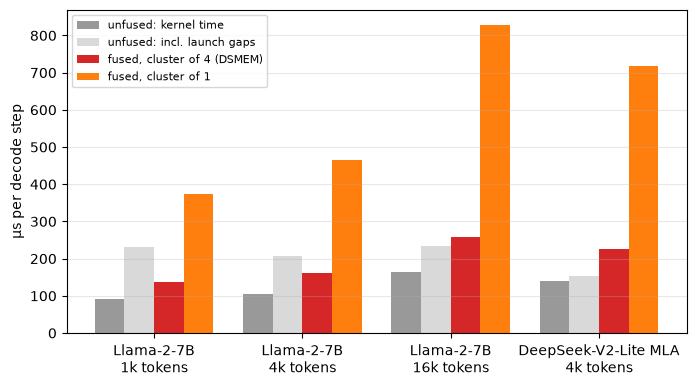

In [13]:
rf.fig_decode_time(L)

- **Kernel time:** the fused DSMEM kernel takes 0.63–0.66× the speed of the unfused sequence (1.1–1.6 vs 1.7–2.5
  TB/s from HBM). 32 clusters of 4 CTAs stream weights more slowly than cuBLAS's GEMVs spread over all 132 SMs.
- **Cluster size 1:** with one CTA per head (32 SMs) the fused kernel is another 2.7–3.2× slower. Splitting heads over
  SMs is what DSMEM buys here.
- **Launch gaps:** the fused kernel only wins once the gaps between 18 eagerly launched kernels are counted. That
  saving comes from having one launch, not from DSMEM, and CUDA graphs would shrink it.

**What would raise the intensity: reuse of the bytes read.** The model below (Llama-2-7B attention block, 4k-token
context) separates the two parts of a decode step.

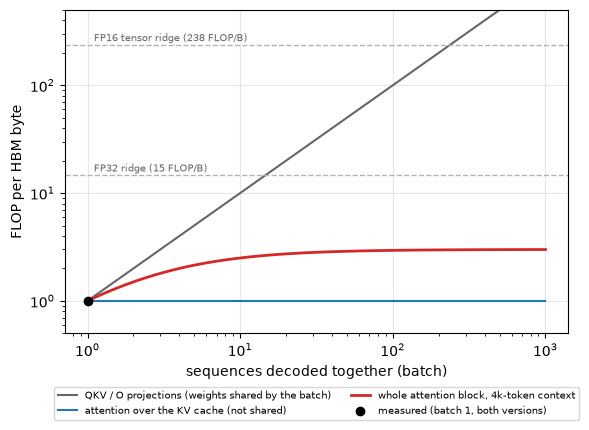

In [14]:
rf.fig_reuse_model(L)

- **Projections (QKV, O):** decoding several sequences together (batching) reuses every weight, so their intensity
  grows with the batch. This is the reuse your intuition points to.
- **Attention over the KV cache:** stays at 1 FLOP/B, because each sequence reads its own cache. Only K/V shared
  across heads raises it (GQA, or MLA's latent cache, which is why DeepSeek's step sits at 5 FLOP/B).
- **The whole block** saturates near 3 FLOP/B at this context length: decode stays memory-bound.
- **Where DSMEM fits:** once several SMs need the same weight tile, DSMEM or multicast can deliver one read to all of
  them. As section 6 shows, that saves L2 traffic, not HBM bytes.

## 8. Top-k with a cluster of 8 (hpc-ops)

Exact top-2048 of a few long rows. The cluster version spreads each row over 8 CTAs and merges their histograms
through DSMEM. The baseline is the library's own non-cluster dispatch: one CTA per row, or a sampled global-memory
split for 240k-element rows.

In [15]:
rf.table_pairs(L, ["hpcops_topk_cluster8"])

- 1.18–1.37× faster at the same bytes. Both versions run far below every roof (2–8 % of HBM bandwidth): with 8–16
  rows, one CTA per row leaves most of the 132 SMs idle.
- This is the one workload whose DSMEM traffic is comparable to its HBM traffic (25–170 %).
- hpc-ops' Lamport RMSNorm is not measured: it needs a multi-GPU broadcast and rejects a single rank.

## 9. FlashAttention-4 backward (reported, B200)

FA4's 2-CTA backward exchanges half of dS (16 KB per iteration) between the two CTAs through DSMEM. It needs Blackwell,
so only the paper's numbers exist: 1457 TFLOP/s non-causal and 1402 TFLOP/s causal on B200, bf16, head dim 128, 16K
tokens (arXiv 2603.05451, Fig. 6). The paper reports no 1-CTA throughput, so there is no pair to compare.

## 10. Cross-check with Nsight Compute's roofline

ncu's own roofline sections were collected for both versions of every pair. The table gives ncu / ours. Red marks
values outside 0.9–1.1.

In [16]:
rf.table_sol_check(L)

- **Bytes:** DRAM bytes agree within 1 % everywhere.
- **Time:** kernel time agrees within 10 % for 62 of 68 configurations.
- **Work:** every red cell is a difference in counted work. ncu counts executed operations:
  - per-CTA repeated work in CREDIT;
  - padded tensor tiles in cuBLAS's decode GEMVs, 2.6–7× the useful FLOPs;
  - ClusterFusion's fused kernels use no tensor core at all, so ncu's tensor point is empty for them.

  We count the work the computation requires.

## Appendix A: per-workload numbers

In [17]:
for w in ["credit_layernorm_backward", "credit_softmax_logits_backward", "credit_pearson_backward",
          "credit_weighted_var_backward", "credit_lars_momentum", "credit_rowwise_quant", "dak_gemm_multicast",
          "deepgemm_fp8_gemm_multicast", "clusterfusion_llama2_7b_decoder", "clusterfusion_deepseek_v2_lite_mla",
          "clusterfusion_rmsnorm"]:
    display(rf.table_pairs(L, [w]))

,,non-DSMEM µs,control µs,DSMEM µs,best P,speedup vs non-DSMEM,HBM bytes DSMEM / non-DSMEM,HBM bytes DSMEM / compulsory,HBM TB/s non-DSMEM,HBM TB/s DSMEM,DSMEM / HBM bytes
workload,shape,,,,,,,,,,
clusterfusion deepseek v2 lite mla,s4k,139.4,717.2,226.6,4,0.62,1.02,1.03,0.23,0.14,0.017


,,non-DSMEM µs,control µs,DSMEM µs,best P,speedup vs non-DSMEM,HBM bytes DSMEM / non-DSMEM,HBM bytes DSMEM / compulsory,HBM TB/s non-DSMEM,HBM TB/s DSMEM,DSMEM / HBM bytes
workload,shape,,,,,,,,,,
clusterfusion rmsnorm,s0,3.1,—,3.8,2,0.82,1.00,0.51,0.35,0.29,0.011


## Appendix B: fixes made to the artifacts before measuring

| artifact | problem (all found by validating against an independent version) | fix |
|---|---|---|
| DAK multicast GEMM | no barrier before the TMA store of the output tile; no cluster barrier before exit while the peer still signals it (crashed under ncu) | two named barriers, one cluster barrier (cost 0.5–2.5 %) |
| ClusterFusion Llama | 32 clusters read and rewrote the same `residual` vector | write to a separate output (as upstream's batch kernel) |
| ClusterFusion Llama | a TMA buffer refilled while other warps still read it (34 of 200 launches corrupted a head) | one block barrier per loop |
| ClusterFusion (both) | DSMEM all-reduce wrote into its send buffer before its outgoing bulk copy had provably read it | one cluster barrier per round (PTX memory model; never observed failing) |
| ClusterFusion, cluster-1 builds | loops hard-coded for cluster 4 computed only part of the result | loop bounds and registers fixed |
| CREDIT (instrumentation only) | timing loop never flushed L2; only the faster one-CTA kernel was reported | environment-controlled flush and kernel selection |

Full entries: `../CLAUDE.md`, change log.